In [1]:
import sys
import pandas as pd

import numpy as np
import mvEEG.mvEEG as mvEEG
import mne_bids


import matplotlib.pyplot as plt
plt.rcParams["svg.fonttype"] = "none"

import seaborn as sns 
from os import path

from glob import glob
import json
import tqdm.auto as ta
import pingouin as pg

%load_ext autoreload
%autoreload 2

In [2]:
ROOT = "../data/derivatives"
DATA_DIR = ROOT
EXPERIMENT_NAME = "banyan"
bad_epochs = (
    {  # epochs which didn't align with eye tracking for one reason or another, and were excluded during preprocessing
        "010": [0, 1, 2, 3],
        "011": [971],
        "017": [1588],
        "031": [1571],
    }
)
old_beh_format = ["001", "002"]
isub_makeup_error_trials = {"001": 2}  # after exclusion, the last n trials which need to be recovered, for now

COND_COUNT_MIN = 60  # minimum number of trials per condition to include subject

wrangl = mvEEG.Wrangler(
    data_dir=DATA_DIR,
    experiment_name=EXPERIMENT_NAME,
    dropped_chans={},
    t_win=50,
    t_step=25,
    trim_timepoints=[-350, 1200],
    trial_bin_size=15,
    n_folds=2,  # NOTE: _not_ using wrangler n_folds here
)

In [3]:
import json

with open("rejected_subs.json", "r") as f:
    rejected_subs = json.load(f)
rejected_subs

['006', '008', '017', '018', '020', '023', '024', '016']

# Performance on main tasks (WM & Spatial Attention)

In [5]:
def load_behavioral_data(wrangl, isub):
    # get all behavioral files for this subject
    filey = wrangl.bids_path.copy().update(
        subject=wrangl.subs[isub], datatype="beh", suffix="beh", description=None, extension=".tsv"
    )
    beh = pd.read_csv(filey.fpath, sep="\t", index_col=0)
    beh = beh.loc[(beh.REJ != True)].reset_index(
        drop=True
    )  # remove real time eye tracking rejects, which aren't in the EEG
    # NOTE on above - redos have REJ column but Nan values for keeps
    beh = beh.drop(bad_epochs.get(wrangl.subs[isub], [])).reset_index(
        drop=True
    )  # drop bad epochs due to sync errors with eye tracking
    beh = beh.loc[~wrangl.artifacts[isub], :].reset_index(
        drop=True
    )  # drop epochs marked as artifacts during preprocessing
    if wrangl.subs[isub] in old_beh_format:
        beh["block_condition"] = beh["Block Condition"]

    return beh


# helper functions to compute K and accuracy by set size for the WM task
def compute_k(accs, changes, ss):
    HR = np.sum(accs * changes) / np.sum(changes)
    FA = np.sum((~accs) * (~changes)) / np.sum(~changes)
    return ss * (HR - FA)


def get_k_by_ss(beh_mem):
    beh_mem.loc[:, "n_targets"] = beh_mem.n_targets.astype(int)  # convert to integers, in case they were strings

    setsizes = sorted(beh_mem.n_targets.unique())
    k_by_ss = {}
    for i, ss in enumerate(setsizes):
        curr_beh = beh_mem.query(f"n_targets=={ss}")
        # get accuracy and change trial info as boolean vectors
        accs = curr_beh.ACC.astype(float).astype(bool).values
        changes = np.array([c == "True" for c in curr_beh["change"].astype(str).values])
        k_by_ss[int(ss)] = compute_k(accs, changes, int(ss))
    return k_by_ss


def get_WM_acc_by_ss(beh_mem):
    beh_mem.loc[:, "n_targets"] = beh_mem.n_targets.astype(int)  # convert to integers, in case they were strings

    setsizes = sorted(beh_mem.n_targets.unique())
    acc_by_ss = {}
    for i, ss in enumerate(setsizes):
        curr_beh = beh_mem.query(f"n_targets=={ss}")
        # get accuracy and change trial info as boolean vectors
        accs = curr_beh.ACC.astype(float).astype(bool).values
        acc_by_ss[int(ss)] = np.mean(accs)
    return acc_by_ss


# helper functions to compute attention probe accuracies and false alarms
def compute_probe_misses(resps):
    n_misses = np.sum(resps == "space")
    n_total = len(resps)
    return n_misses / n_total


def get_probe_misses_by_ss(beh_attn):
    beh_attn = beh_attn[
        beh_attn.relevant_num.notna()
    ].copy()  # keep only trials where a probe number was presented, regardless of during delay or at test (SS0)
    beh_attn.loc[:, "n_targets"] = beh_attn.n_targets.astype(int)  # convert to integers, in case they were strings

    setsizes = sorted(beh_attn.n_targets.unique())
    miss_by_ss = {}
    for i, ss in enumerate(setsizes):
        curr_beh = beh_attn.query(f"n_targets=={ss}")
        try:
            resps = curr_beh.RESP.values
            miss_by_ss[int(ss)] = compute_probe_misses(resps)
        except Exception as e:
            miss_by_ss[int(ss)] = np.nan
    return miss_by_ss


def get_probe_accs_by_ss(beh_attn):
    beh_attn = beh_attn[
        beh_attn.relevant_num.notna()
    ].copy()  # keep only trials where a probe number was presented, regardless of during delay or at test (SS0)
    try:
        beh_attn = beh_attn.query(
            "RESP != 'space'"
        )  # keep only trials where subject made a response (i.e., didn't miss)
    except Exception as e:
        print(f"Error querying RESP != 'space': {e}")
        print("will compute accuracy including all trials")

    beh_attn.loc[:, "n_targets"] = beh_attn.n_targets.astype(int)  # convert to integers, in case they were strings

    setsizes = sorted(beh_attn.n_targets.unique())
    acc_by_ss = {}
    for i, ss in enumerate(setsizes):
        curr_beh = beh_attn.query(f"n_targets=={ss}")
        # get accuracy info as boolean vectors
        accs = curr_beh.ACC.astype(float).astype(bool).values
        acc_by_ss[int(ss)] = np.mean(accs)
    return acc_by_ss


def get_probe_FAs_by_ss(beh_attn):
    beh_attn = beh_attn[beh_attn.relevant_num.isna()].copy()  # keep only trials where no probe number was presented
    beh_attn.loc[:, "n_targets"] = beh_attn.n_targets.astype(int)  # convert to integers, in case they were strings

    setsizes = sorted(beh_attn.n_targets.unique())
    fa_by_ss = {}
    for i, ss in enumerate(setsizes):
        curr_beh = beh_attn.query(f"n_targets=={ss}")
        # get false alarm info as boolean vectors
        fas = curr_beh.ACC.astype(float).astype(bool).values
        fa_by_ss[int(ss)] = 1 - np.mean(fas)  # FA rate is 1 - accuracy when no probe is presented
    return fa_by_ss

In [6]:
WM_accs = {}
WM_ks = {}
Attn_probe_accs = {}  # given a probe digit appears and was responded to, was it correctly identified as odd/even
Attn_probe_misses = {}  # given a probe appears, was it missed (i.e., identified as absent when present)
Attn_noProbe_FAs = {}  # given no probe appears, was it incorrectly identified as present

for isub in ta.tqdm(range(wrangl.nsub)):

    if wrangl.subs[isub] in rejected_subs:
        print(f"Skipping {wrangl.subs[isub]} due to rejection in trial counts or behavioral analyses, check notebook 0")
        continue

    # Load the data
    Xdata, ydata = wrangl.load_eeg(isub, reject=True)

    beh = load_behavioral_data(wrangl, isub)
    assert Xdata.shape[0] == beh.shape[0], "Mismatch between EEG epochs and behavioral data"
    if wrangl.subs[isub] in isub_makeup_error_trials:
        beh = beh.iloc[: -isub_makeup_error_trials[wrangl.subs[isub]], :].reset_index(
            drop=True
        )  # drop last n trials to make up for lost trials during recording error
        Xdata = Xdata[: -isub_makeup_error_trials[wrangl.subs[isub]], :, :]
        ydata = ydata[: -isub_makeup_error_trials[wrangl.subs[isub]]]
    beh = beh.loc[beh.loc[:, "n_targets"].isin(["2", "4", "6", "8", 2, 4, 6, 8])]  # drop some broken makeup trials
    # print the number of trials without proves by condition (task, set size)
    no_probe_cond_counts = beh[beh.relevant_num.isna()].trial_condition.value_counts()
    if np.any(no_probe_cond_counts <= COND_COUNT_MIN):
        print(f"WARNING: Subject {wrangl.subs[isub]} has insufficient no-probe trials in at least one condition.")
        print(no_probe_cond_counts)
    else:
        WM_accs[wrangl.subs[isub]] = get_WM_acc_by_ss(beh.query("block_condition=='memory'"))
        WM_ks[wrangl.subs[isub]] = get_k_by_ss(beh.query("block_condition=='memory'"))
        Attn_probe_accs[wrangl.subs[isub]] = get_probe_accs_by_ss(beh.query("block_condition=='attention'"))
        Attn_probe_misses[wrangl.subs[isub]] = get_probe_misses_by_ss(beh.query("block_condition=='attention'"))
        Attn_noProbe_FAs[wrangl.subs[isub]] = get_probe_FAs_by_ss(beh.query("block_condition=='attention'"))

  0%|          | 0/34 [00:00<?, ?it/s]

Error querying RESP != 'space': name 'RESP' is not defined
will compute accuracy including all trials
Skipping 006 due to rejection in trial counts or behavioral analyses, check notebook 0
Skipping 008 due to rejection in trial counts or behavioral analyses, check notebook 0
Skipping 016 due to rejection in trial counts or behavioral analyses, check notebook 0
Skipping 017 due to rejection in trial counts or behavioral analyses, check notebook 0
Skipping 018 due to rejection in trial counts or behavioral analyses, check notebook 0
Skipping 020 due to rejection in trial counts or behavioral analyses, check notebook 0
Skipping 023 due to rejection in trial counts or behavioral analyses, check notebook 0
Skipping 024 due to rejection in trial counts or behavioral analyses, check notebook 0


In [7]:
json.dump(WM_ks, open("k_estimates.json", "w"))

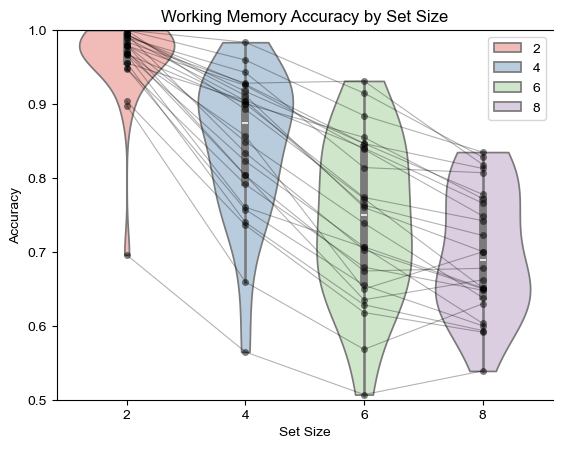

In [8]:
acc_df = (
    pd.DataFrame(WM_accs)
    .reset_index()
    .melt(id_vars=["index"], var_name="Subject", value_name="Accuracy")
    .rename(columns={"index": "Set Size"})
)
ax = sns.violinplot(data=acc_df, x="Set Size", y="Accuracy", cut=0, hue="Set Size", palette="Pastel1")
plt.title("Working Memory Accuracy by Set Size")
ax.set_ylim(0.5, 1)
sns.despine(right=True, top=False)
# plot strip plots of participants at each set size
sns.stripplot(data=acc_df, x="Set Size", y="Accuracy", color="k", alpha=0.5, jitter=False, size=5)

for sub in acc_df.Subject.unique():
    sub_data = acc_df.query(f"Subject=='{sub}'")
    plt.plot(
        [0, 1, 2, 3],  # hack to get the x positions of the violin/strip plots
        sub_data["Accuracy"],
        color="k",
        alpha=0.3,
        linewidth=0.8,
    )

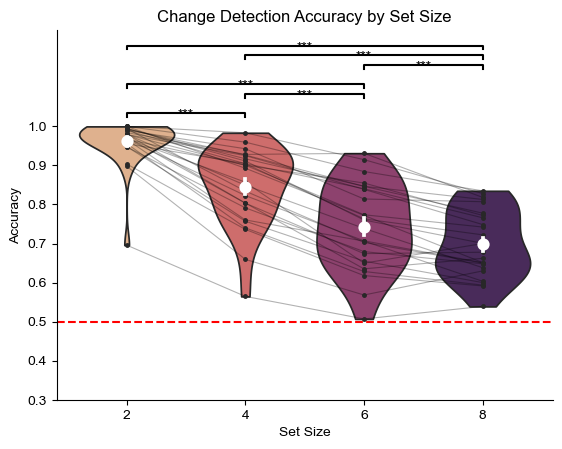

In [9]:
acc_df = (
    pd.DataFrame(WM_accs)
    .reset_index()
    .melt(id_vars=["index"], var_name="Subject", value_name="Accuracy")
    .rename(columns={"index": "Set Size"})
)
ax = sns.violinplot(data=acc_df, x="Set Size", y="Accuracy", cut=0, hue="Set Size", palette="flare", inner="point")
plt.title("Working Memory Accuracy by Set Size")
# ax.set_ylim(0.5, 1)
# sns.despine(right=True, top=False)

# plot lines connecting each participant across each set size
for sub in acc_df.Subject.unique():
    sub_data = acc_df.query(f"Subject=='{sub}'")
    plt.plot(
        [0, 1, 2, 3],  # hack to get the x positions of the violin/strip plots
        sub_data["Accuracy"],
        color="k",
        alpha=0.3,
        linewidth=0.8,
    )

_ = sns.pointplot(data=acc_df, x="Set Size", y="Accuracy", color="w", linestyle="none", zorder=100, errorbar="se")

acc_ttests_res = pg.pairwise_tests(data=acc_df, dv="Accuracy", within="Set Size", subject="Subject", padjust="bonf")

loc_map = {2: 0, 4: 1, 6: 2, 8: 3}

# significant pairwise comparisons
sig_df = acc_ttests_res.loc[acc_ttests_res["p-corr"] < 0.05, ["A", "B", "p-corr"]].copy()
sig_df["A"] = sig_df["A"].astype(int)
sig_df["B"] = sig_df["B"].astype(int)
sig_df["x1"] = sig_df["A"].map(loc_map)
sig_df["x2"] = sig_df["B"].map(loc_map)
sig_df = sig_df.dropna(subset=["x1", "x2"]).copy()

sig_df[["x1", "x2"]] = np.sort(sig_df[["x1", "x2"]].values, axis=1)
sig_df["left"] = sig_df["x1"]
sig_df["right"] = sig_df["x2"]

right_order = sorted(sig_df["right"].unique())
sig_df["level"] = np.nan
next_base_level = 0
for r in right_order:
    idx = sig_df.index[sig_df["right"] == r]
    idx_sorted = sig_df.loc[idx].sort_values("left", ascending=False).index.tolist()
    for j, row_idx in enumerate(idx_sorted):
        sig_df.loc[row_idx, "level"] = next_base_level + j
    next_base_level += len(idx_sorted) + 1
sig_df["level"] = sig_df["level"].astype(int)

y_min, y_max = acc_df["Accuracy"].min(), acc_df["Accuracy"].max()
y_range = y_max - y_min if y_max > y_min else 1.0
y_base = y_max + 0.05 * y_range
level_step = 0.05 * y_range
h = 0.02 * y_range

for _, row in sig_df.iterrows():
    x1, x2 = row["x1"], row["x2"]
    y = y_base + row["level"] * level_step
    p_val = row["p-corr"]

    ax.plot([x1, x1, x2, x2], [y, y + h, y + h, y], lw=1.5, c="k")
    sig = "***" if p_val < 0.001 else "**" if p_val < 0.01 else "*"
    ax.text((x1 + x2) / 2, y - 0.01, sig, ha="center", va="bottom", color="k")

_ = plt.axhline(0.5, color="r", linestyle="--", zorder=-1)
plt.title("Change Detection Accuracy by Set Size")
plt.legend([], [], frameon=False)
sns.despine(right=True, top=True)

if len(sig_df) > 0:
    top_y = y_base + sig_df["level"].max() * level_step + h
    ax.set_ylim(y_min - 0.02 * y_range, top_y + 0.08 * y_range)

ax.set_yticks([0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9, 1.0])
plt.savefig("figures/behavior_change_detection_accuracy_by_setsize.png", dpi=300, bbox_inches="tight", transparent=True)

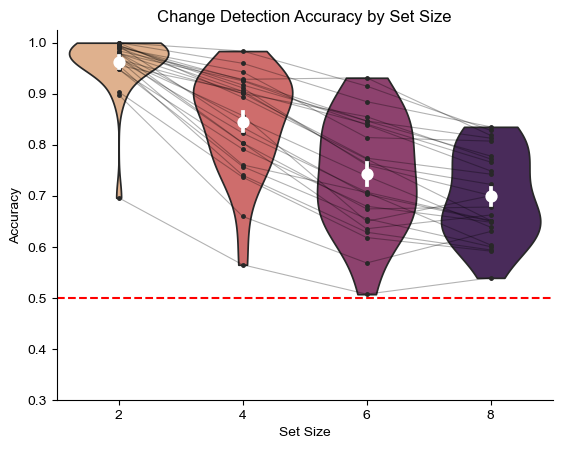

In [10]:
loc_map = {0: 0, 1: 1, 2: 2, 3: 3, 4: 4, 6: 5, 8: 6}

ax = sns.violinplot(
    data=acc_df,
    x="Set Size",
    y="Accuracy",
    cut=0,
    hue="Set Size",
    palette="flare",
    inner="point",
)

# plot lines connecting each participant across each set size
for sub in acc_df.Subject.unique():
    sub_data = acc_df.query(f"Subject=='{sub}'")
    plt.plot(
        [0, 1, 2, 3],  # hack to get the x positions of the violin/strip plots
        sub_data["Accuracy"],
        color="k",
        alpha=0.3,
        linewidth=0.8,
    )

sns.pointplot(
    data=acc_df,
    x="Set Size",
    y="Accuracy",
    color="w",
    linestyle="none",
    zorder=100,
    errorbar="se",
)

ns_df = acc_ttests_res.loc[acc_ttests_res["p-corr"] > 0.05, ["A", "B", "p-corr"]].copy()

ns_df["x1"] = ns_df["A"].astype(int).map(loc_map)
ns_df["x2"] = ns_df["B"].astype(int).map(loc_map)
ns_df = ns_df.dropna(subset=["x1", "x2"]).copy()

ns_df[["x1", "x2"]] = np.sort(ns_df[["x1", "x2"]].values, axis=1)
ns_df["level"] = range(len(ns_df))

y_min = acc_df["Accuracy"].min()
y_max = acc_df["Accuracy"].max()
y_range = max(y_max - y_min, 1.0)
y_base = y_max + 0.05 * y_range
level_step = 0.06 * y_range
h = 0.02 * y_range

for _, row in ns_df.iterrows():
    x1, x2 = row["x1"], row["x2"]
    y = y_base + row["level"] * level_step

    ax.plot([x1, x1, x2, x2], [y, y + h, y + h, y], color="k", lw=1.2)
    ax.text(
        (x1 + x2) / 2,
        y + h,
        "n.s.",
        ha="center",
        va="bottom",
        color="k",
    )

ax.axhline(0.5, color="r", linestyle="--", zorder=-1)
ax.set_title("Change Detection Accuracy by Set Size")
ax.legend([], [], frameon=False)
sns.despine(right=True, top=True)

if not ns_df.empty:
    top_y = y_base + ns_df["level"].max() * level_step + h
    ax.set_ylim(y_min - 0.02 * y_range, top_y + 0.08 * y_range)

ax.set_yticks([0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9, 1.0])
plt.savefig(
    "figures/behavior_change_detection_accuracy_by_setsize_ns.png",
    dpi=300,
    bbox_inches="tight",
    transparent=True,
)

In [11]:
acc_df.pivot(index="Subject", columns="Set Size", values="Accuracy").to_csv(
    "behavior_files/WM_acc_by_ss_pivot.csv", index=True
)

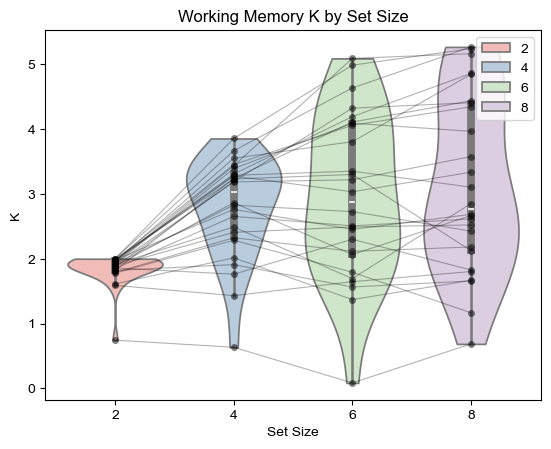

In [12]:
k_df = (
    pd.DataFrame(WM_ks)
    .reset_index()
    .melt(id_vars=["index"], var_name="Subject", value_name="K")
    .rename(columns={"index": "Set Size"})
)
ax = sns.violinplot(data=k_df, x="Set Size", y="K", cut=0, hue="Set Size", palette="Pastel1")
plt.title("Working Memory K by Set Size")
_ = sns.stripplot(data=k_df, x="Set Size", y="K", color="k", alpha=0.5, jitter=False, size=5)
# add a line per participant
for sub in k_df.Subject.unique():
    sub_data = k_df.query(f"Subject=='{sub}'")
    plt.plot(
        [0, 1, 2, 3],  # hack to get the x positions of the violin/strip plots
        sub_data["K"],
        color="k",
        alpha=0.3,
        linewidth=0.8,
    )

In [13]:
k_df.pivot(index="Subject", columns="Set Size", values="K").to_csv("behavior_files/WM_k_by_ss_pivot.csv", index=True)

In [14]:
import pingouin as pg

# map set sizes to x-axis locations
loc_map = {
    2: 0,
    4: 1,
    6: 2,
    8: 3,
}

In [15]:
ttests_res = pg.pairwise_tests(
    data=k_df[k_df["Set Size"] > 0], dv="K", within="Set Size", subject="Subject", padjust="bonf"
)

ttests_res

,Contrast,A,B,Paired,Parametric,T,dof,alternative,p-unc,p-corr,p-adjust,BF10,hedges
0,Set Size,2,4,True,True,-8.111306,25.0,two-sided,1.824807e-08,1.094884e-07,bonf,7.36e+05,-1.621964
1,Set Size,2,6,True,True,-5.119057,25.0,two-sided,2.739731e-05,1.643839e-04,bonf,859.8,-1.210540
2,Set Size,2,8,True,True,-5.329729,25.0,two-sided,1.591732e-05,9.550391e-05,bonf,1408.729,-1.301294
3,Set Size,4,6,True,True,-1.362616,25.0,two-sided,1.851535e-01,1.000000e+00,bonf,0.473,-0.165828
4,Set Size,4,8,True,True,-2.215625,25.0,two-sided,3.605092e-02,2.163055e-01,bonf,1.639,-0.309111
5,Set Size,6,8,True,True,-1.758326,25.0,two-sided,9.093015e-02,5.455809e-01,bonf,0.794,-0.127854


,A,B,p-corr,x1,x2
0,2,4,1.094884e-07,0,1
1,2,6,1.643839e-04,0,2
2,2,8,9.550391e-05,0,3


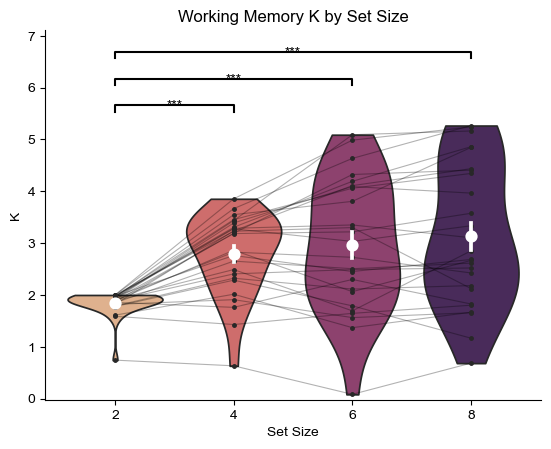

In [16]:
k_df = (
    pd.DataFrame(WM_ks)
    .reset_index()
    .melt(id_vars=["index"], var_name="Subject", value_name="K")
    .rename(columns={"index": "Set Size"})
)

ax = sns.violinplot(data=k_df, x="Set Size", y="K", cut=0, hue="Set Size", palette="flare", inner="point")
plt.title("Working Memory K by Set Size")
# _ = sns.stripplot(data=k_df, x="Set Size", y="K", color="k", alpha=0.5, jitter=False, size=5)

# add a line per participant
for sub in k_df.Subject.unique():
    sub_data = k_df.query(f"Subject=='{sub}'")
    plt.plot(
        [0, 1, 2, 3],  # x positions of the violin/strip plots
        sub_data["K"],
        color="k",
        alpha=0.3,
        linewidth=0.8,
    )

_ = sns.pointplot(data=k_df, x="Set Size", y="K", color="w", linestyle="none", zorder=100, errorbar="se")


# map set sizes to x-axis locations
loc_map = {
    2: 0,
    4: 1,
    6: 2,
    8: 3,
}

ttests_res = pg.pairwise_tests(
    data=k_df[k_df["Set Size"] > 0], dv="K", within="Set Size", subject="Subject", padjust="bonf"
)

# keep only significant comparisons and convert to plotting coordinates
sig_df = ttests_res.loc[ttests_res["p-corr"] < 0.05, ["A", "B", "p-corr"]].copy()
sig_df["x1"] = sig_df["A"].map(loc_map)
sig_df["x2"] = sig_df["B"].map(loc_map)
display(sig_df)
sig_df = sig_df.dropna(subset=["x1", "x2"]).copy()

# ensure left-to-right ordering for interval logic
sig_df[["x1", "x2"]] = np.sort(sig_df[["x1", "x2"]].values, axis=1)
sig_df["left"] = sig_df["x1"]
sig_df["right"] = sig_df["x2"]

# stack by highest compared set size (right endpoint),
# and within each endpoint, shorter comparisons lower and wider ones above.
right_order = sorted(sig_df["right"].unique())
sig_df["level"] = np.nan
next_base_level = 0

for r in right_order:
    idx = sig_df.index[sig_df["right"] == r]
    # larger left endpoint -> shorter span -> lower
    idx_sorted = sig_df.loc[idx].sort_values("left", ascending=False).index.tolist()
    for j, row_idx in enumerate(idx_sorted):
        sig_df.loc[row_idx, "level"] = next_base_level + j

    # move to a fresh vertical band so different right-endpoint groups never overlap
    next_base_level += len(idx_sorted) + 1

sig_df["level"] = sig_df["level"].astype(int)

# data-driven y placement so bars never sit on top of the violins
y_min, y_max = k_df["K"].min(), k_df["K"].max()
y_range = y_max - y_min if y_max > y_min else 1.0
y_base = y_max + 0.05 * y_range
level_step = 0.05 * y_range
h = 0.025 * y_range

# draw bars + significance text
for _, row in sig_df.iterrows():
    x1, x2 = row["x1"], row["x2"]
    y = y_base + row["level"] * level_step
    p_val = row["p-corr"]
    col = "k"

    ax.plot([x1, x1, x2, x2], [y, y + h, y + h, y], lw=1.5, c=col)

    if p_val < 0.001:
        sig = "***"
    elif p_val < 0.01:
        sig = "**"
    elif p_val < 0.05:
        sig = "*"
    else:
        sig = "ns"

    ax.text((x1 + x2) / 2, y, sig, ha="center", va="bottom", color=col)

# expand y-limits to include the highest bracket
if len(sig_df) > 0:
    top_y = y_base + sig_df["level"].max() * level_step + h
    ax.set_ylim(y_min - 0.02 * y_range, top_y + 0.08 * y_range)

plt.legend([], [], frameon=False)  # remove legend
sns.despine(right=True, top=True)
plt.savefig("figures/behavior_WM_k_by_setsize.png", dpi=300, bbox_inches="tight", transparent=True)

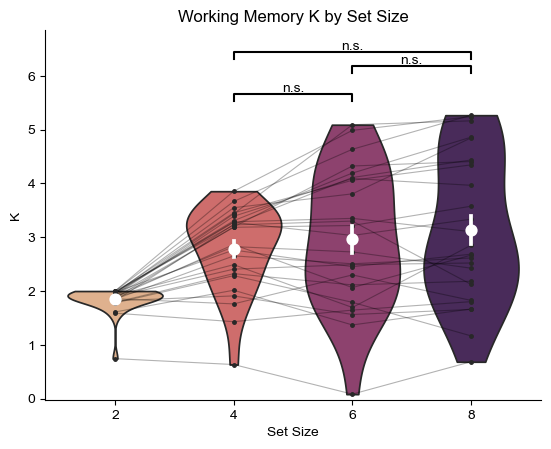

In [17]:
k_df = (
    pd.DataFrame(WM_ks)
    .reset_index()
    .melt(id_vars=["index"], var_name="Subject", value_name="K")
    .rename(columns={"index": "Set Size"})
).query("`Set Size` > 0")

ax = sns.violinplot(data=k_df, x="Set Size", y="K", cut=0, hue="Set Size", palette="flare", inner="point")
plt.title("Working Memory K by Set Size")
# _ = sns.stripplot(data=k_df, x="Set Size", y="K", color="k", alpha=0.5, jitter=False, size=5)

# add a line per participant
for sub in k_df.Subject.unique():
    sub_data = k_df.query(f"Subject=='{sub}'")
    plt.plot(
        [0, 1, 2, 3],  # x positions of the violin/strip plots
        sub_data["K"],
        color="k",
        alpha=0.3,
        linewidth=0.8,
    )

_ = sns.pointplot(data=k_df, x="Set Size", y="K", color="w", linestyle="none", zorder=100, errorbar="se")


# map set sizes to x-axis locations
loc_map = {
    2: 0,
    4: 1,
    6: 2,
    8: 3,
}

ttests_res = pg.pairwise_tests(
    data=k_df[k_df["Set Size"] > 0], dv="K", within="Set Size", subject="Subject", padjust="bonf"
)

# Keep only non-significant comparisons
ns_df = ttests_res.loc[ttests_res["p-corr"] > 0.05, ["A", "B", "p-corr"]].copy()

ns_df["x1"] = ns_df["A"].astype(int).map(loc_map)
ns_df["x2"] = ns_df["B"].astype(int).map(loc_map)
ns_df = ns_df.dropna(subset=["x1", "x2"]).copy()

ns_df[["x1", "x2"]] = np.sort(ns_df[["x1", "x2"]].values, axis=1)
ns_df["left"] = ns_df["x1"]
ns_df["right"] = ns_df["x2"]

# Stack bars by right endpoint
ns_df["level"] = np.nan
next_base_level = 0

for right in sorted(ns_df["right"].unique()):
    idx = ns_df.index[ns_df["right"] == right]
    idx_sorted = ns_df.loc[idx].sort_values("left", ascending=False).index

    for level, row_idx in enumerate(idx_sorted):
        ns_df.loc[row_idx, "level"] = next_base_level + level

    next_base_level += len(idx_sorted) + 1

ns_df["level"] = ns_df["level"].astype(int)

y_min, y_max = k_df["K"].min(), k_df["K"].max()
y_range = y_max - y_min if y_max > y_min else 1.0
y_base = y_max + 0.05 * y_range
level_step = 0.05 * y_range
h = 0.025 * y_range

for _, row in ns_df.iterrows():
    x1, x2 = row["x1"], row["x2"]
    y = y_base + row["level"] * level_step

    ax.plot(
        [x1, x1, x2, x2],
        [y, y + h, y + h, y],
        lw=1.5,
        color="k",
    )
    ax.text(
        (x1 + x2) / 2,
        y + h,
        "n.s.",
        ha="center",
        va="bottom",
        color="k",
    )

if not ns_df.empty:
    top_y = y_base + ns_df["level"].max() * level_step + h
    ax.set_ylim(y_min - 0.02 * y_range, top_y + 0.08 * y_range)

plt.title("Working Memory K by Set Size")
plt.legend([], [], frameon=False)
sns.despine(right=True, top=True)
plt.savefig(
    "figures/behavior_WM_k_by_setsize_ns.png",
    dpi=300,
    bbox_inches="tight",
    transparent=True,
)

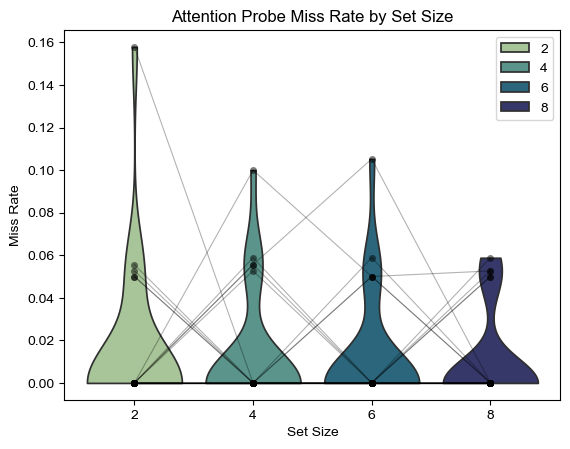

In [18]:
probe_misses_df = (
    pd.DataFrame(Attn_probe_misses)
    .reset_index()
    .melt(id_vars=["index"], var_name="Subject", value_name="Miss Rate")
    .rename(columns={"index": "Set Size"})
)
ax = sns.violinplot(data=probe_misses_df, x="Set Size", y="Miss Rate", cut=0, hue="Set Size", palette="crest")
plt.title("Attention Probe Miss Rate by Set Size")
_ = sns.stripplot(data=probe_misses_df, x="Set Size", y="Miss Rate", color="k", alpha=0.5, jitter=False, size=5)
for sub in probe_misses_df.Subject.unique():
    sub_data = probe_misses_df.query(f"Subject=='{sub}'")
    plt.plot(
        [0, 1, 2, 3],  # hack to get the x positions of the violin/strip plots
        sub_data["Miss Rate"],
        color="k",
        alpha=0.3,
        linewidth=0.8,
    )
plt.savefig("figures/Attn_probe_miss_rate_by_set_size.png", dpi=300, bbox_inches="tight", transparent=True)

In [19]:
probe_misses_df[probe_misses_df["Miss Rate"] > 0.2]

,Set Size,Subject,Miss Rate


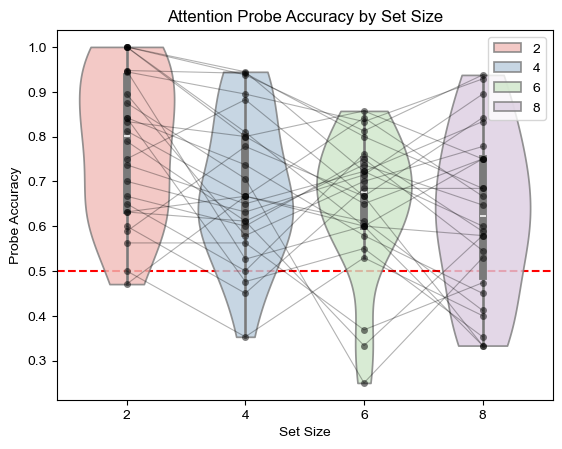

In [20]:
probe_accs_df = (
    pd.DataFrame(Attn_probe_accs)
    .reset_index()
    .melt(id_vars=["index"], var_name="Subject", value_name="Probe Accuracy")
    .rename(columns={"index": "Set Size"})
)
ax = sns.violinplot(
    data=probe_accs_df, x="Set Size", y="Probe Accuracy", cut=0, hue="Set Size", palette="Pastel1", alpha=0.8
)
plt.title("Attention Probe Accuracy by Set Size")
_ = sns.stripplot(data=probe_accs_df, x="Set Size", y="Probe Accuracy", color="k", alpha=0.5, jitter=False, size=5)
for sub in probe_accs_df.Subject.unique():
    sub_data = probe_accs_df.query(f"Subject=='{sub}'")
    plt.plot(
        [0, 1, 2, 3],  # hack to get the x positions of the violin/strip plots
        sub_data["Probe Accuracy"],
        color="k" if sub not in rejected_subs else "r",
        alpha=0.3,
        linewidth=0.8,
    )
_ = plt.axhline(0.5, color="r", linestyle="--", label="Chance Level", zorder=-1)

In [21]:
probe_accs_df.pivot(index="Subject", columns="Set Size", values="Probe Accuracy").to_csv(
    "behavior_files/Attn_probe_acc_by_ss_pivot.csv", index=True
)

/opt/homebrew/Caskroom/miniforge/base/envs/preproc_pype/lib/python3.12/site-packages/pingouin/pairwise.py:28: UserWarning: pairwise_ttests is deprecated, use pairwise_tests instead.
  warnings.warn("pairwise_ttests is deprecated, use pairwise_tests instead.", UserWarning)


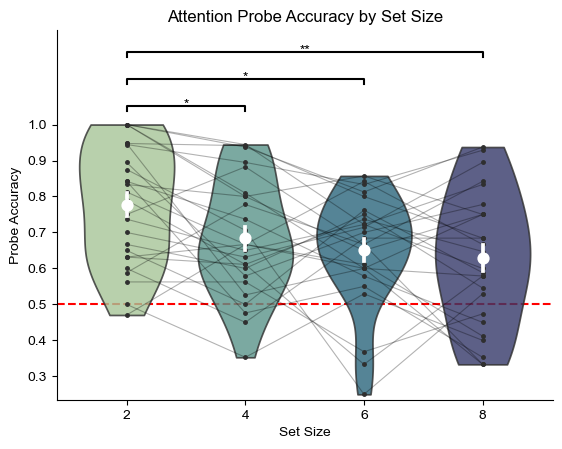

In [22]:
probe_ttests_res = pg.pairwise_ttests(
    data=probe_accs_df,
    dv="Probe Accuracy",
    within="Set Size",
    subject="Subject",
    padjust="bonf",
)

ax = sns.violinplot(
    data=probe_accs_df,
    x="Set Size",
    y="Probe Accuracy",
    cut=0,
    hue="Set Size",
    palette="crest",
    alpha=0.8,
    inner="point",
)


for sub in probe_accs_df["Subject"].unique():
    sub_data = probe_accs_df.query(f"Subject=='{sub}'").sort_values("Set Size")
    xvals = sub_data["Set Size"].map(loc_map).values
    plt.plot(xvals, sub_data["Probe Accuracy"].values, color="k", alpha=0.3, linewidth=0.8)

_ = sns.pointplot(
    data=probe_accs_df,
    x="Set Size",
    y="Probe Accuracy",
    color="w",
    linestyle="none",
    zorder=100,
    errorbar="se",
)

# significant pairwise comparisons
sig_df = probe_ttests_res.loc[probe_ttests_res["p-corr"] < 0.05, ["A", "B", "p-corr"]].copy()
sig_df["A"] = sig_df["A"].astype(int)
sig_df["B"] = sig_df["B"].astype(int)
sig_df["x1"] = sig_df["A"].map(loc_map)
sig_df["x2"] = sig_df["B"].map(loc_map)
sig_df = sig_df.dropna(subset=["x1", "x2"]).copy()

sig_df[["x1", "x2"]] = np.sort(sig_df[["x1", "x2"]].values, axis=1)
sig_df["left"] = sig_df["x1"]
sig_df["right"] = sig_df["x2"]

right_order = sorted(sig_df["right"].unique())
sig_df["level"] = np.nan
next_base_level = 0
for r in right_order:
    idx = sig_df.index[sig_df["right"] == r]
    idx_sorted = sig_df.loc[idx].sort_values("left", ascending=False).index.tolist()
    for j, row_idx in enumerate(idx_sorted):
        sig_df.loc[row_idx, "level"] = next_base_level + j
    next_base_level += len(idx_sorted) + 1
sig_df["level"] = sig_df["level"].astype(int)

y_min, y_max = probe_accs_df["Probe Accuracy"].min(), probe_accs_df["Probe Accuracy"].max()
y_range = y_max - y_min if y_max > y_min else 1.0
y_base = y_max + 0.05 * y_range
level_step = 0.05 * y_range
h = 0.02 * y_range

for _, row in sig_df.iterrows():
    x1, x2 = row["x1"], row["x2"]
    y = y_base + row["level"] * level_step
    p_val = row["p-corr"]

    ax.plot([x1, x1, x2, x2], [y, y + h, y + h, y], lw=1.5, c="k")
    sig = "***" if p_val < 0.001 else "**" if p_val < 0.01 else "*"
    ax.text((x1 + x2) / 2, y + 0.001, sig, ha="center", va="bottom", color="k")

_ = plt.axhline(0.5, color="r", linestyle="--", zorder=-1)
plt.title("Attention Probe Accuracy by Set Size")
plt.legend([], [], frameon=False)
sns.despine(right=True, top=True)

if len(sig_df) > 0:
    top_y = y_base + sig_df["level"].max() * level_step + h
    ax.set_ylim(y_min - 0.02 * y_range, top_y + 0.08 * y_range)
ax.set_yticks([0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9, 1.0])
plt.savefig("figures/behavior_attention_probe_accuracy_by_setsize.png", dpi=300, bbox_inches="tight", transparent=True)

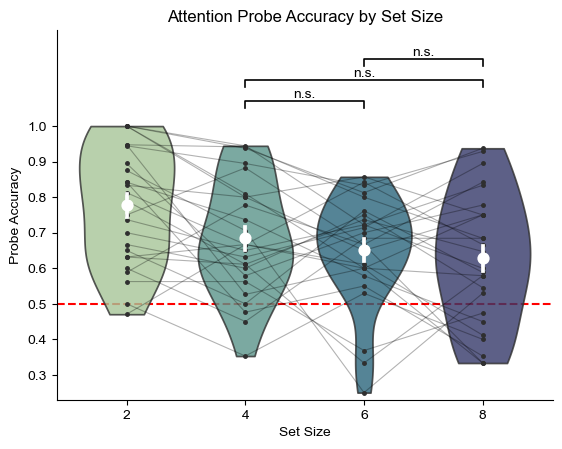

In [ ]:
# Plot attention probe accuracy with non-significant comparisons labeled "n.s."
ax = sns.violinplot(
    data=probe_accs_df,
    x="Set Size",
    y="Probe Accuracy",
    cut=0,
    hue="Set Size",
    palette="crest",
    alpha=0.8,
    inner="point",
)


for sub in probe_accs_df["Subject"].unique():
    sub_data = probe_accs_df.query(f"Subject=='{sub}'").sort_values("Set Size")
    xvals = sub_data["Set Size"].map(loc_map).values
    plt.plot(xvals, sub_data["Probe Accuracy"].values, color="k", alpha=0.3, linewidth=0.8)

_ = sns.pointplot(
    data=probe_accs_df,
    x="Set Size",
    y="Probe Accuracy",
    color="w",
    linestyle="none",
    zorder=100,
    errorbar="se",
)

sig_df = probe_ttests_res.loc[probe_ttests_res["p-corr"] > 0.05, ["A", "B", "p-corr"]].copy()

sig_df["x1"] = sig_df["A"].astype(int).map(loc_map)
sig_df["x2"] = sig_df["B"].astype(int).map(loc_map)
sig_df = sig_df.dropna(subset=["x1", "x2"])

sig_df[["x1", "x2"]] = np.sort(sig_df[["x1", "x2"]].values, axis=1)
sig_df["level"] = range(len(sig_df))

y_min = probe_accs_df["Probe Accuracy"].min()
y_max = probe_accs_df["Probe Accuracy"].max()
y_range = max(y_max - y_min, 1.0)
y_base = y_max + 0.05 * y_range
level_step = 0.06 * y_range
h = 0.02 * y_range

for _, row in sig_df.iterrows():
    x1, x2 = row["x1"], row["x2"]
    y = y_base + row["level"] * level_step

    ax.plot([x1, x1, x2, x2], [y, y + h, y + h, y], color="k", lw=1.2)
    ax.text((x1 + x2) / 2, y + h, "n.s.", ha="center", va="bottom", color="k")

ax.axhline(0.5, color="r", linestyle="--", zorder=-1)
ax.set_title("Attention Probe Accuracy by Set Size")
ax.legend([], [], frameon=False)
sns.despine(right=True, top=True)

if not sig_df.empty:
    top_y = y_base + sig_df["level"].max() * level_step + h
    ax.set_ylim(y_min - 0.02 * y_range, top_y + 0.08 * y_range)

ax.set_yticks([0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9, 1.0])
plt.savefig(
    "figures/behavior_attention_probe_accuracy_by_setsize_ns.png",
    dpi=300,
    bbox_inches="tight",
    transparent=True,
)

In [25]:
# for each set size, test whether probe accuracy is above chance (0.5) using a one-sample t-test
for ss in sorted(probe_accs_df["Set Size"].unique()):
    ss_data = probe_accs_df[probe_accs_df["Set Size"] == ss]["Probe Accuracy"].values
    ttest_res = pg.ttest(ss_data, 0.5, alternative="greater")
    print(f"Set Size {ss}: t={ttest_res.loc['T-test', 'T']:.3f}, p={ttest_res.loc['T-test', 'p-val']:.4f}")

Set Size 2: t=8.556, p=0.0000
Set Size 4: t=5.809, p=0.0000
Set Size 6: t=5.035, p=0.0000
Set Size 8: t=3.538, p=0.0008


In [ ]:
probe_accs_df[probe_accs_df["Set Size"] == 2]

,Set Size,Subject,Probe Accuracy
0,2,001,1.000000
4,2,002,0.562500
8,2,003,0.736842
12,2,004,0.842105
16,2,005,0.750000
20,2,007,0.631579
24,2,009,1.000000
28,2,010,0.944444
32,2,011,0.588235
36,2,012,0.500000


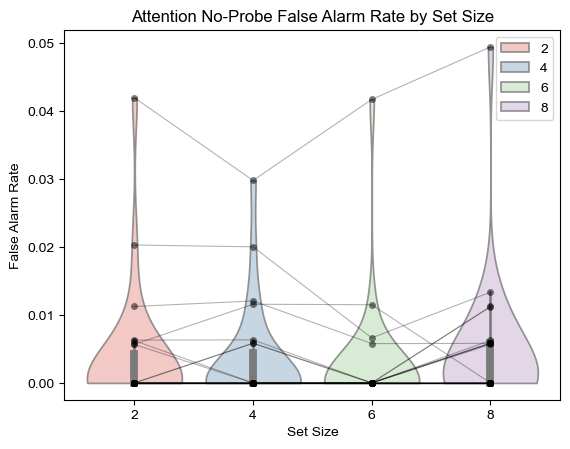

In [ ]:
probe_FAs_df = (
    pd.DataFrame(Attn_noProbe_FAs)
    .reset_index()
    .melt(id_vars=["index"], var_name="Subject", value_name="False Alarm Rate")
    .rename(columns={"index": "Set Size"})
)
ax = sns.violinplot(
    data=probe_FAs_df, x="Set Size", y="False Alarm Rate", cut=0, hue="Set Size", palette="Pastel1", alpha=0.8
)
plt.title("Attention No-Probe False Alarm Rate by Set Size")
_ = sns.stripplot(data=probe_FAs_df, x="Set Size", y="False Alarm Rate", color="k", alpha=0.5, jitter=False, size=5)
for sub in probe_FAs_df.Subject.unique():
    sub_data = probe_FAs_df.query(f"Subject=='{sub}'")
    plt.plot(
        [0, 1, 2, 3],  # hack to get the x positions of the violin/strip plots
        sub_data["False Alarm Rate"],
        color="k",
        alpha=0.3,
        linewidth=0.8,
    )

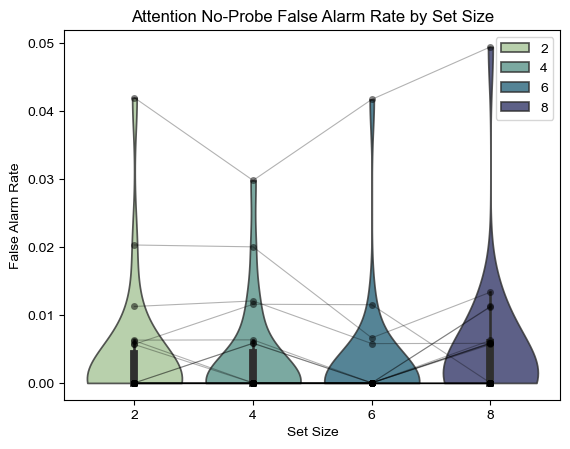

In [ ]:
probe_FAs_df = (
    pd.DataFrame(Attn_noProbe_FAs)
    .reset_index()
    .melt(id_vars=["index"], var_name="Subject", value_name="False Alarm Rate")
    .rename(columns={"index": "Set Size"})
)
ax = sns.violinplot(
    data=probe_FAs_df, x="Set Size", y="False Alarm Rate", cut=0, hue="Set Size", palette="crest", alpha=0.8
)
plt.title("Attention No-Probe False Alarm Rate by Set Size")
_ = sns.stripplot(data=probe_FAs_df, x="Set Size", y="False Alarm Rate", color="k", alpha=0.5, jitter=False, size=5)
for sub in probe_FAs_df.Subject.unique():
    sub_data = probe_FAs_df.query(f"Subject=='{sub}'")
    plt.plot(
        [0, 1, 2, 3],  # hack to get the x positions of the violin/strip plots
        sub_data["False Alarm Rate"],
        color="k",
        alpha=0.3,
        linewidth=0.8,
    )
plt.savefig("figures/behavior_attention_noProbe_FA_by_setsize.png", dpi=300, bbox_inches="tight", transparent=True)

In [ ]:
probe_FAs_df[probe_FAs_df["False Alarm Rate"] > 0.1]

,Set Size,Subject,False Alarm Rate


# Correlating Spatial Attention and WM K Performance

In [ ]:
sub_ks = k_df[k_df["Set Size"] > 3].groupby("Subject")["K"].mean()
sub_ks

Subject
001    4.523043
002    0.467553
003    4.563474
004    3.815850
005    1.962259
007    2.591679
009    4.119600
010    3.952438
011    3.974817
012    1.683720
013    4.067394
014    2.206395
015    3.247262
019    2.531496
021    1.747674
022    3.927771
025    2.345275
026    4.694689
027    2.659426
028    2.884594
029    2.472925
030    2.633565
031    1.710298
032    3.326319
033    3.214891
034    1.626160
Name: K, dtype: float64

In [ ]:
sub_probe_accs = probe_accs_df[probe_accs_df["Set Size"] > 3].groupby("Subject")["Probe Accuracy"].mean()
sub_probe_accs

Subject
001    0.802381
002    0.468202
003    0.657407
004    0.588596
005    0.627451
007    0.725146
009    0.895833
010    0.885547
011    0.762183
012    0.427451
013    0.625439
014    0.533333
015    0.733333
019    0.685575
021    0.495098
022    0.665004
025    0.563181
026    0.662824
027    0.746867
028    0.459711
029    0.507797
030    0.833333
031    0.606140
032    0.631818
033    0.808462
034    0.616713
Name: Probe Accuracy, dtype: float64

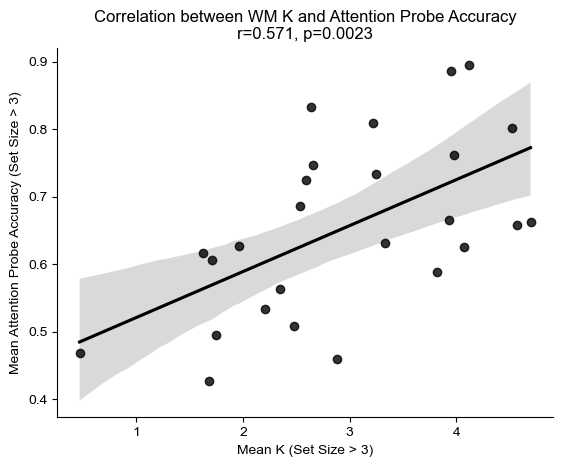

In [ ]:
from scipy.stats import pearsonr

corr_res = pearsonr(sub_ks, sub_probe_accs)
sns.regplot(x=sub_ks, y=sub_probe_accs, color="k")
plt.xlabel("Mean K (Set Size > 3)")
plt.ylabel("Mean Attention Probe Accuracy (Set Size > 3)")
plt.title(f"Correlation between WM K and Attention Probe Accuracy\nr={corr_res[0]:.3f}, p={corr_res[1]:.4f}")
sns.despine()
plt.savefig("figures/correlation_K_probe_accuracy.png", dpi=300, bbox_inches="tight", transparent=True)